+ матрицы регулярные
+ работаем с нулевым кодовым словом
+ $r = \frac{1}{2} = \frac{k}{n}$ - design ratio, или скорость как нам Алексей с Павлом говорили
+ $p$ - вероятность ошибки
+ $l = l_\text{avg} = L(1)$ - количество связей у variable node
+ $n_0 = r_\text{avg} = R(1)$ - количество связей у check node

+ $\rho(x) = \frac{R'(x)}{R'(1)} = \sum_{i = 1}^{r_{max}}\rho_i x^{i - 1} = (x)^{n_0 - 1}$
+ $t$ - threshold, некоторое достаточное количество check node указывающих на ошибку, обычно хотя бы больше половины
+ $p_\text{c.n.} = \frac{1 - \rho(1 - 2p)}{2}$ - вероятность того, что check node указывает на ошибку
+ $p_\text{v.n.} = \sum_{i = t}^l \binom{l}{i} p_\text{c.n.}^i (1 - p_\text{c.n.})^{l - i}$ - вероятность того, что variable node ошибочный

Идея алгоритма density evolution состоит в том, чтобы мы рассчитали вероятность ошибки в variable node используя вероятность ошибки в канале, а в последующих итерациях мы подставляли вероятность ошибки в variable node из предыдущей итерации и снова считали

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from DE.DE import density_evolution, density_evolution_f, density_evolution_p

path = 'data/H_matrix/H4_100x150.txt'

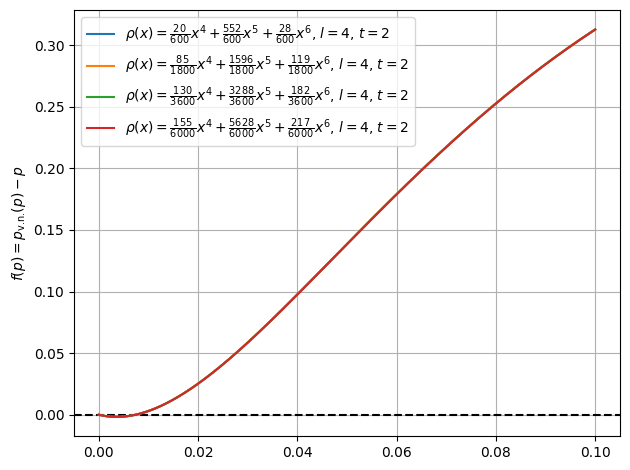

In [2]:
plt.axhline(0, color='black', linestyle='--')
plt.grid()
density_evolution_f(np.loadtxt(path, delimiter=','))
density_evolution_f(np.loadtxt('data/H_matrix/H4_300x450.txt', delimiter=','))
density_evolution_f(np.loadtxt('data/H_matrix/H4_600x900.txt', delimiter=','))
density_evolution_f(np.loadtxt('data/H_matrix/H4_1000x1500.txt', delimiter=','))
plt.ylabel('$f(p) = p_\\text{v.n.}(p) - p$')
plt.legend()
plt.tight_layout()
plt.savefig('de_full.pdf')

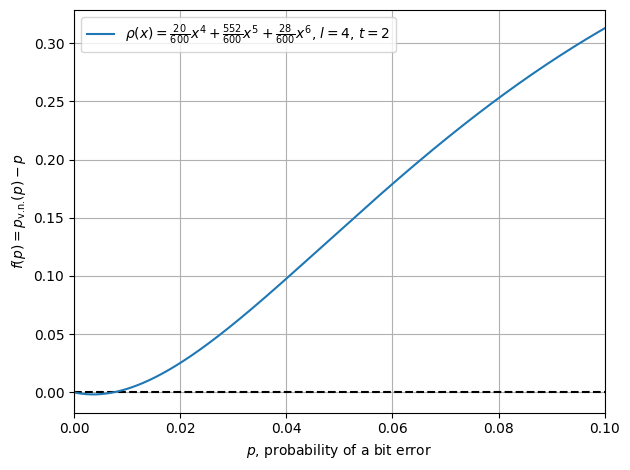

In [3]:
plt.axhline(0, color='black', linestyle='--')
plt.grid()
density_evolution_f(np.loadtxt(path, delimiter=','))
plt.xlabel('$p$, probability of a bit error')
plt.ylabel('$f(p) = p_\\text{v.n.}(p) - p$')
plt.legend()
plt.xlim((0, 0.1))
plt.tight_layout()
plt.savefig('de_f.pdf')

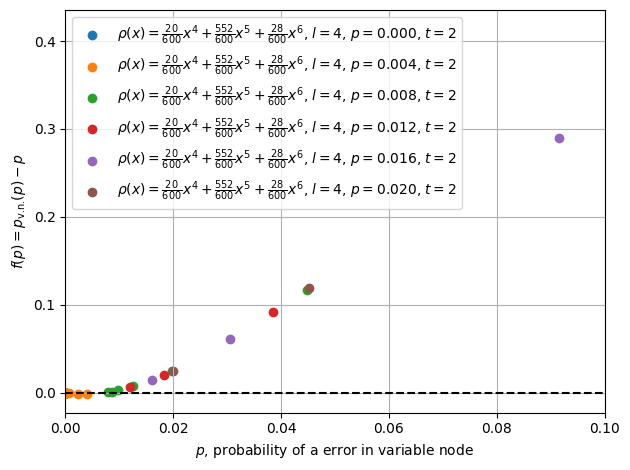

In [15]:
plt.axhline(0, color='black', linestyle='--')
plt.grid()
density_evolution(np.loadtxt(path, delimiter=','))
plt.xlabel('$p$, probability of a error in variable node')
plt.ylabel('$f(p) = p_\\text{v.n.}(p) - p$')
plt.legend()
plt.xlim((0, 0.1))
plt.tight_layout()
plt.savefig('de.pdf')

In [4]:
from decoder.Decoder import Decoder

deep = 100
repeat = 100

H = np.loadtxt(path, dtype=np.int8, delimiter=',')
c = np.zeros(H.shape[1], dtype=np.int16)
p = np.linspace(0, 0.05, 30)
ber1 = Decoder.bitflipping_decoding_for_many(H, c, p=p, repeat=repeat, deep=deep, ber=True, with_threshold=True)
ber2 = Decoder.bitflipping_decoding_for_many(
    np.loadtxt('data/H_matrix/H4_300x450.txt', delimiter=','), 
    np.zeros(450, dtype=np.int16), 
    p=p, 
    repeat=repeat, 
    deep=deep, 
    ber=True, 
    with_threshold=True
)
ber3 = Decoder.bitflipping_decoding_for_many(
    np.loadtxt('data/H_matrix/H4_600x900.txt', delimiter=','), 
    np.zeros(900, dtype=np.int16), 
    p=p, 
    repeat=repeat, 
    deep=deep, 
    ber=True, 
    with_threshold=True
)
ber4 = Decoder.bitflipping_decoding_for_many(
    np.loadtxt('data/H_matrix/H4_1000x1500.txt', delimiter=','), 
    np.zeros(1500, dtype=np.int16), 
    p=p, 
    repeat=repeat, 
    deep=deep, 
    ber=True, 
    with_threshold=True
)
plt.plot(p, ber1, label=f'{path}')
plt.plot(p, ber2, label=f'{'data/H_matrix/H4_300x450.txt'}')
plt.plot(p, ber3, label=f'{'data/H_matrix/H4_600x900.txt'}')
plt.plot(p, ber4, label=f'{'data/H_matrix/H4_1000x1500.txt'}')
density_evolution_p(np.loadtxt(path, delimiter=','), p, 1000)
plt.legend(loc='lower left')
plt.ylabel('BER')
plt.xlabel('Вероятность ошибки в канале')
plt.yscale('log')
plt.grid()
plt.tight_layout()
plt.savefig('data/H_log.png')
plt.show()

KeyboardInterrupt: 

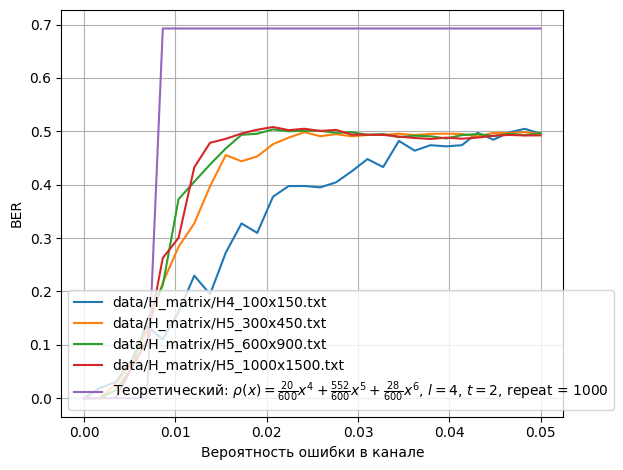

In [17]:
plt.plot(p, ber1, label=f'{path}')
plt.plot(p, ber2, label=f'{'data/H_matrix/H5_300x450.txt'}')
plt.plot(p, ber3, label=f'{'data/H_matrix/H5_600x900.txt'}')
plt.plot(p, ber4, label=f'{'data/H_matrix/H5_1000x1500.txt'}')
density_evolution_p(np.loadtxt(path, delimiter=','), p, 1000)
plt.legend(loc='lower left')
plt.ylabel('BER')
plt.xlabel('Вероятность ошибки в канале')
plt.grid()
plt.tight_layout()
plt.savefig('data/H_lin.png')
plt.show()

In [3]:
from matrix_generators.Gallager import GallagerMatrixGenerator

H4_500_1000 = GallagerMatrixGenerator.generate(500, 1000, 5)
H4_700_1400 = GallagerMatrixGenerator.generate(700, 1400, 5)
H4_900_1800 = GallagerMatrixGenerator.generate(900, 1800, 5)
H4_1100_2200 = GallagerMatrixGenerator.generate(1100, 2200, 5)

H4_500_1000.shape

10
10
10
10


(500, 1000)

In [4]:
print(np.mean(H4_500_1000.sum(axis=1)))
np.unique(H4_500_1000.sum(axis=1))

10.0


array([10])

In [4]:
np.mean(H4_500_1000.sum(axis=0))
np.unique(H4_500_1000.sum(axis=0))

array([5])

In [4]:
H3_300_600 = GallagerMatrixGenerator.generate(300, 600, 3)
H4_300_600 = GallagerMatrixGenerator.generate(300, 600, 4)
H5_300_600 = GallagerMatrixGenerator.generate(300, 600, 5)
H6_300_600 = GallagerMatrixGenerator.generate(300, 600, 6)
H7_700_1400 = GallagerMatrixGenerator.generate(700, 1400, 7)

6
8
10
12
14


/var/folders/z0/8b45wnpd2gj56v8yj5whv3mc0000gn/T/ipykernel_1916/3935402439.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


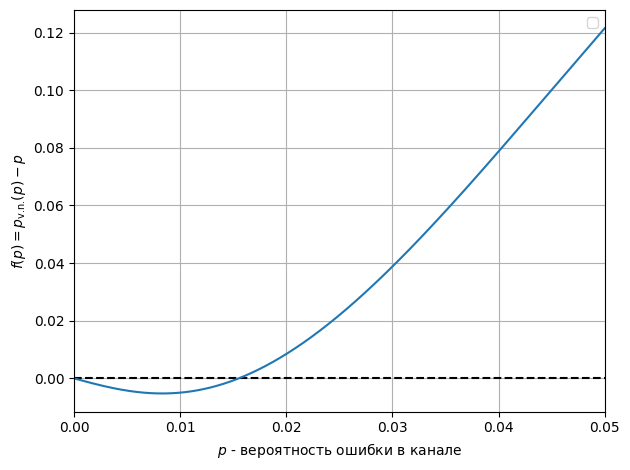

In [13]:
plt.axhline(0, color='black', linestyle='--')
p = np.linspace(0, 0.05, 1000)
plt.grid()
plt.plot(p, density_evolution_p(H4_500_1000, p, 1) - p)
plt.ylabel('$f(p) = p_\\text{v.n.}(p) - p$')
plt.xlabel('$p$ - вероятность ошибки в канале')
plt.xlim(0.0, 0.05)
plt.legend()
plt.tight_layout()
plt.savefig('de_full.pdf')

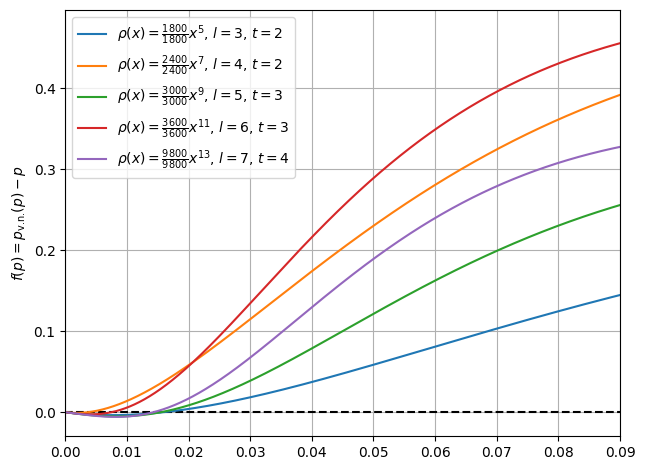

In [54]:
plt.axhline(0, color='black', linestyle='--')
plt.grid()
density_evolution_f(H3_300_600)
density_evolution_f(H4_300_600)
density_evolution_f(H5_300_600)
density_evolution_f(H6_300_600)
density_evolution_f(H7_700_1400)
plt.ylabel('$f(p) = p_\\text{v.n.}(p) - p$')
plt.legend()
plt.tight_layout()
plt.xlim((0.0, 0.09))
plt.savefig('1.pdf')

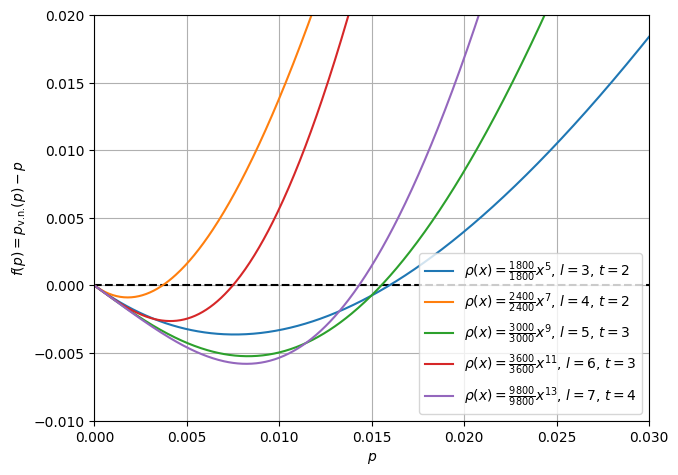

In [55]:
plt.axhline(0, color='black', linestyle='--')
plt.grid()
density_evolution_f(H3_300_600)
density_evolution_f(H4_300_600)
density_evolution_f(H5_300_600)
density_evolution_f(H6_300_600)
density_evolution_f(H7_700_1400)
plt.ylabel('$f(p) = p_\\text{v.n.}(p) - p$')
plt.xlabel('$p$')
plt.legend()
plt.tight_layout()
plt.xlim((0.0, 0.03))
plt.ylim((-0.01, 0.02))
plt.savefig('2.pdf')

In [3]:
from matrix_generators.Gallager import GallagerMatrixGenerator

H3_90_180 = GallagerMatrixGenerator.generate(90, 180, 3)
H3_270_540 = GallagerMatrixGenerator.generate(270, 540, 3)
H3_540_1080 = GallagerMatrixGenerator.generate(540, 1080, 3)
H3_900_1800 = GallagerMatrixGenerator.generate(900, 1800, 3)

6
6
6
6


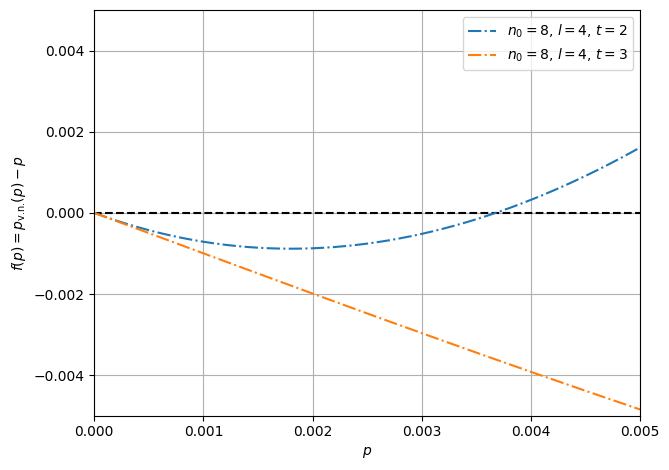

In [20]:
from DE.DE import density_evolution, density_evolution_f, density_evolution_p

p = np.linspace(0, 0.05, 1000)
plt.axhline(0, color='black', linestyle='--')
plt.grid()
plt.plot(p, density_evolution_p(H4_300_600, p, 1, 2) - p, '-.', label='$n_0 = 8$, $l = 4$, $t = 2$')
plt.plot(p, density_evolution_p(H4_300_600, p, 1, 3) - p, '-.', label='$n_0 = 8$, $l = 4$, $t = 3$')
plt.ylabel('$f(p) = p_\\text{v.n.}(p) - p$')
plt.xlabel('$p$')
plt.legend()
plt.tight_layout()
plt.xlim((0.0, 0.005))
plt.ylim((-0.005, 0.005))
plt.savefig('2.pdf')

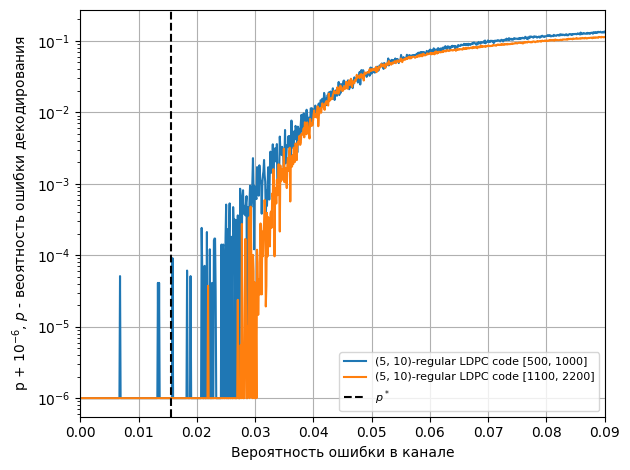

In [10]:
from decoder.Decoder import Decoder

# deep = 100
# repeat = 100
# p = np.linspace(0, 0.1, 1000)
# with_threshold = False
# ber = True

# ber11 = Decoder.bitflipping_decoding_for_many(
#     H4_500_1000, 
#     np.zeros(1000, dtype=np.int16), 
#     p=p, 
#     repeat=repeat, 
#     deep=deep, 
#     ber=ber, 
#     with_threshold=with_threshold
# )
# ber22 = Decoder.bitflipping_decoding_for_many(
#     H4_700_1400, 
#     np.zeros(1400, dtype=np.int16), 
#     p=p, 
#     repeat=repeat, 
#     deep=deep, 
#     ber=ber, 
#     with_threshold=with_threshold
# )
# ber33 = Decoder.bitflipping_decoding_for_many(
#     H4_900_1800, 
#     np.zeros(1800, dtype=np.int16), 
#     p=p, 
#     repeat=repeat, 
#     deep=deep, 
#     ber=ber, 
#     with_threshold=with_threshold
# )
# ber44 = Decoder.bitflipping_decoding_for_many(
#     H4_1100_2200, 
#     np.zeros(2200, dtype=np.int16), 
#     p=p, 
#     repeat=repeat, 
#     deep=deep, 
#     ber=ber, 
#     with_threshold=with_threshold
# )
plt.plot(p, ber11 + 1e-6, label=f'(5, 10)-regular LDPC code [500, 1000]')
# plt.plot(p, ber22 + 1e-6, label=f'(5, 10)-regular LDPC code [700, 1400]')
# plt.plot(p, ber33 + 1e-6, label=f'(5, 10)-regular LDPC code [900, 1800]')
plt.plot(p, ber44 + 1e-6, label=f'(5, 10)-regular LDPC code [1100, 2200]')
# plt.plot(p, density_evolution_p(H4_500_1000, p, 2), '-.', label='$p_{vn}$ на 2м перерасчете')
# plt.plot(p, density_evolution_p(H4_500_1000, p, 3), '-.', label='$p_{vn}$ на 3м перерасчете')
# plt.plot(p, density_evolution_p(H4_500_1000, p, 50), '-.', label='$p_{vn}$ на 50м перерасчете')
plt.axvline(np.sort(p[density_evolution_p(H4_500_1000, p, 1) - p > 0])[0], color='black', linestyle='--', label='$p^*$')
plt.legend(loc='lower right', fontsize=8)
plt.ylabel('p + $10^{-6}$, $p$ - веоятность ошибки декодирования')
plt.xlabel('Вероятность ошибки в канале')
plt.yscale('log')
plt.xlim((0.0, 0.09))
plt.grid()
plt.tight_layout()
plt.savefig('data/H2.pdf')
plt.show()

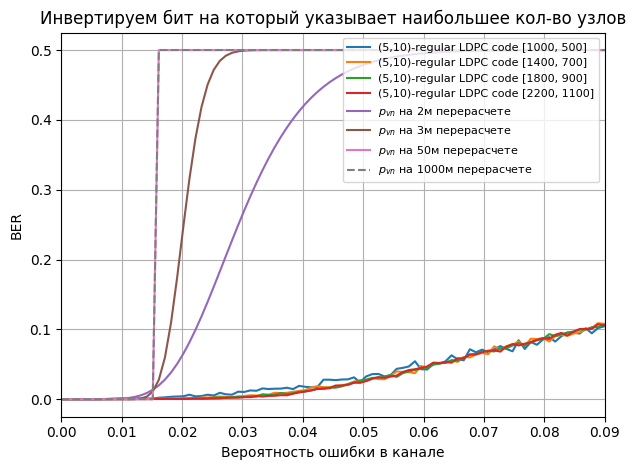

In [51]:
plt.plot(p, ber11, label=f'(5,10)-regular LDPC code [1000, 500]')
plt.plot(p, ber22, label=f'(5,10)-regular LDPC code [1400, 700]')
plt.plot(p, ber33, label=f'(5,10)-regular LDPC code [1800, 900]')
plt.plot(p, ber44, label=f'(5,10)-regular LDPC code [2200, 1100]')
plt.plot(p, density_evolution_p(H4_500_1000, p, 2), label='$p_{vn}$ на 2м перерасчете')
plt.plot(p, density_evolution_p(H4_500_1000, p, 3), label='$p_{vn}$ на 3м перерасчете')
plt.plot(p, density_evolution_p(H4_500_1000, p, 50), label='$p_{vn}$ на 50м перерасчете')
plt.plot(p, density_evolution_p(H4_500_1000, p, 1000), '--', label='$p_{vn}$ на 1000м перерасчете')
plt.legend(loc='upper right', fontsize=8)
plt.title('Инвертируем бит на который указывает наибольшее кол-во узлов')
plt.ylabel('BER')
plt.xlabel('Вероятность ошибки в канале')
plt.xlim((0.0, 0.09))
plt.grid()
plt.tight_layout()
plt.savefig('data/H.pdf')
plt.show()

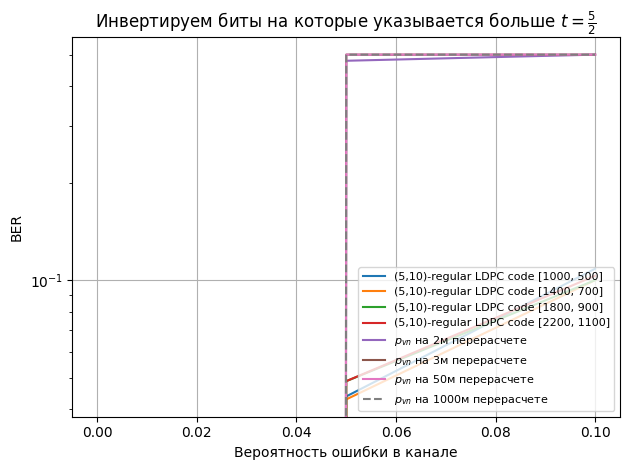

In [8]:
from decoder.Decoder import Decoder

deep = 10
repeat = 10

c = np.zeros(H4_500_1000.shape[1], dtype=np.int16)
p = np.linspace(0, 0.1, 3)
ber1 = Decoder.bitflipping_decoding_for_many(H4_500_1000, c, p=p, repeat=repeat, deep=deep, ber=True, with_threshold=False)
ber2 = Decoder.bitflipping_decoding_for_many(
    H4_700_1400, 
    np.zeros(1400, dtype=np.int16), 
    p=p, 
    repeat=repeat, 
    deep=deep, 
    ber=True, 
    with_threshold=False
)
ber3 = Decoder.bitflipping_decoding_for_many(
    H4_900_1800, 
    np.zeros(1800, dtype=np.int16), 
    p=p, 
    repeat=repeat, 
    deep=deep, 
    ber=True, 
    with_threshold=False
)
ber4 = Decoder.bitflipping_decoding_for_many(
    H4_1100_2200, 
    np.zeros(2200, dtype=np.int16), 
    p=p, 
    repeat=repeat, 
    deep=deep, 
    ber=True, 
    with_threshold=False
)
plt.plot(p, ber1, label=f'(5,10)-regular LDPC code [1000, 500]')
plt.plot(p, ber2, label=f'(5,10)-regular LDPC code [1400, 700]')
plt.plot(p, ber3, label=f'(5,10)-regular LDPC code [1800, 900]')
plt.plot(p, ber4, label=f'(5,10)-regular LDPC code [2200, 1100]')
plt.plot(p, density_evolution_p(H4_500_1000, p, 2), label='$p_{vn}$ на 2м перерасчете')
plt.plot(p, density_evolution_p(H4_500_1000, p, 3), label='$p_{vn}$ на 3м перерасчете')
plt.plot(p, density_evolution_p(H4_500_1000, p, 50), label='$p_{vn}$ на 50м перерасчете')
plt.plot(p, density_evolution_p(H4_500_1000, p, 1000), '--', label='$p_{vn}$ на 1000м перерасчете')
plt.legend(loc='lower right', fontsize=8)
plt.title('Инвертируем биты на которые указывается больше $t = \\frac{5}{2}$')
# plt.xlim((0.0, 0.045))
plt.ylabel('BER')
plt.xlabel('Вероятность ошибки в канале')
plt.yscale('log')
plt.grid()
plt.tight_layout()
plt.savefig('data/H_log_threshold.pdf')
plt.show()